# Reproduction: *Solanum betaceum* Cav fruit maturity detection with YOLO11 (minimal one-fold demonstration)

**Paper:** "Detection of *Solanum betaceum* Cav fruit maturity using YOLO11-based deep learning",
*Frontiers in Plant Science* 17:1880899 (2026), DOI [10.3389/fpls.2026.1880899](https://doi.org/10.3389/fpls.2026.1880899) — [PMC13614014](https://pmc.ncbi.nlm.nih.gov/articles/PMC13614014/)

**Data:** Zenodo **version 1.0** record [10.5281/zenodo.21167174](https://doi.org/10.5281/zenodo.21167174)
(concept DOI 10.5281/zenodo.21167173, CC-BY-4.0), `project-2-Berenjena.zip`
(761,724,227 bytes, md5 `bef30c09a389809059a6bed7ace1cf43`) — the complete raw dataset the
authors' own notebook unzips. (The record's later version ships only truncated takeout archives:
a partial fold_4 image sample without labels, plus figures/results files.)

**Author code (pinned, parameter evidence):** [omercruz-sys/YOLO11---Solanum-betaceum-Cav-](https://github.com/omercruz-sys/YOLO11---Solanum-betaceum-Cav-) @ commit `2a9ca4d97bb830b53cd240fccbe5a7fcc9e6ca3d`.

**Execution status: EXECUTED (partial reproduction).** The notebook ran end-to-end without errors on a fresh Colab T4 GPU; see the final section for the honest observed result vs the paper's Table 6.

## Scope of this notebook (exact)

Reconstruct **fold 1** per paper §2.1.1 (200 images → 160 train / 20 val / 20 test, seeded),
normalize all images to **640×640 (PIL LANCZOS)** exactly as the authors' notebook does (their
step 1.1), apply a **paper-faithful class balancing** (§2.2.2 + Tables 2/3; see the balancing
section for why the authors' released balancing code cannot produce the paper's stated
distribution), then fine-tune **YOLO11n** for the paper's headline **300 epochs** with the paper's
exact hyperparameters (Table 1), and evaluate per-class Precision / Recall / mAP50 / mAP50-95 on
the fold-1 20-image **test** subset against the paper's Table 6 five-fold means for YOLO11n.

**Out of scope:** folds 2–5, YOLO11s/m, 100/200-epoch budgets, the statistical comparison
(Table 7). A single fold is *not* a verification of dataset-level means; Table 6 itself reports
fold-to-fold sd up to ±0.06 mAP50-95.

**Documented adaptations** (details at each cell):
1. The authors never published the val/test assignment (their split code yields 160/40, the paper
   states 160/20/20); we assign 20/20 deterministically with `random.Random(42)`. Our fold-1
   **train** set provably matches the paper's (its instance counts 870 green / 163 ripe equal
   Table 3's "Original" fold-1 row exactly).
2. **Balancing is an AI-assisted adaptation (ADAPTED BALANCING).** The authors' released balancing
   code, run verbatim on this exact training set, yields 932 green / 348 ripe instances —
   contradicting the paper's own Table 3 (603 green / 503 ripe). Its under-sampling mixes instance
   and file counts, so it cannot reach the paper's distribution. We therefore implement §2.2.2 as
   described, targeting the paper's published fold-1 counts, with augmentation transforms taken
   verbatim from the authors' cell.
3. The paper §2.2.2 additionally lists zoom 0.8–1.2 and 0–10% edge cropping, which neither the
   released code nor this adaptation applies — recorded as an author code/paper discrepancy.

**実行内容(日本語):** 論文の§2.1.1に従いfold 1(160/20/20、シード42)を再構築し(著者のtrain構成と
インスタンス数870/163が完全一致することを検証済み)、§2.2.2+Table 3に基づくクラスバランシング
(著者公開コードではTable 3の分布が得られないため、AIが適応実装)をtrainに適用後、
Table 1のハイパーパラメータでYOLO11nを300エポック学習し、テスト20枚のクラス別指標を
Table 6のYOLO11n平均と比較します。fold 2–5・YOLO11s/m・統計検定は対象外です。

## Runtime selection — T4 GPU required / ランタイム選択

This notebook **trains** a detector; it must run on a **GPU (T4)** runtime.
In Colab: `Runtime → Change runtime type → T4 GPU`. Estimated (not measured): ≈5–15 min
setup + 761 MB download, ≈30–75 min training, a few minutes evaluation.

**このノートブックは学習を行うためT4 GPUランタイムが必要です。** 「ランタイム → ランタイムのタイプを変更 → T4 GPU」を選択してください。
概算: セットアップ+761MBのダウンロード 約5–15分、学習 約30–75分、評価は数分。

In [ ]:
import sys, torch
print("Python:", sys.version.split()[0])
print("torch:", torch.__version__)
cuda_ok = torch.cuda.is_available()
print("CUDA available:", cuda_ok)
if cuda_ok:
    print("GPU:", torch.cuda.get_device_name(0))
if not cuda_ok:
    raise RuntimeError(
        "No GPU detected. This reproduction trains YOLO11n and requires a T4 GPU runtime: "
        "Runtime > Change runtime type > T4 GPU. (CPU training for 300 epochs is impractical.)"
    )

Python: 3.13.15
torch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


## Setup — pin the paper's Ultralytics version / セットアップ(論文と同じUltralytics版)

The paper trained with **Ultralytics 8.4.99** (Python 3.12 / PyTorch 2.8+cu128 on Lightning AI
H100). We pin `ultralytics==8.4.99` and use Colab's preinstalled CUDA-enabled PyTorch; no heavy
source build. Expected result: printed version `8.4.99`.

In [ ]:
%pip install -q ultralytics==8.4.99
import ultralytics
print("ultralytics:", ultralytics.__version__)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.1/42.1 kB 2.8 MB/s eta 0:00:00


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 33.2 MB/s eta 0:00:00


Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


ultralytics: 8.4.99


## Download the raw dataset (Zenodo version 1.0) / 生データのダウンロード

The complete raw dataset is `project-2-Berenjena.zip` in Zenodo **version 1.0** (record 21167174,
CC-BY-4.0) — exactly the archive the authors' notebook unzips in its first cell. We verify the
exact byte size and MD5 advertised by the record before use. Expected result: `MD5 OK` after a
~762 MB streamed download.

In [ ]:
import hashlib, requests
from pathlib import Path

ZENODO_URL = "https://zenodo.org/api/records/21167174/files/project-2-Berenjena.zip/content"
EXPECTED_SIZE = 761_724_227
EXPECTED_MD5 = "bef30c09a389809059a6bed7ace1cf43"
zip_path = Path("/content/project-2-Berenjena.zip")

if not zip_path.exists():
    with requests.get(ZENODO_URL, stream=True, timeout=1800) as r:
        r.raise_for_status()
        h = hashlib.md5()
        n = 0
        with open(zip_path, "wb") as f:
            for chunk in r.iter_content(chunk_size=1 << 20):
                f.write(chunk)
                h.update(chunk)
                n += len(chunk)
                if n % (64 << 20) < (1 << 20):
                    print(f"  downloaded {n/1e6:.0f} MB", flush=True)
print("size:", zip_path.stat().st_size, "expected:", EXPECTED_SIZE)
digest = hashlib.md5(zip_path.read_bytes()).hexdigest()
print("md5:", digest)
assert zip_path.stat().st_size == EXPECTED_SIZE, "size mismatch — do not use this download"
assert digest == EXPECTED_MD5, "md5 mismatch — do not use this download"
print("MD5 OK")

  downloaded 67 MB


  downloaded 134 MB


  downloaded 201 MB


  downloaded 268 MB


  downloaded 336 MB


...

  downloaded 604 MB


  downloaded 671 MB


  downloaded 738 MB


size: 761724227 expected: 761724227


md5: bef30c09a389809059a6bed7ace1cf43
MD5 OK


## Unzip and verify the raw dataset / 展開と検証

The paper states **200 annotated images** (§2.1) with YOLO-format labels. The zip's internal
layout is not visible from metadata, so we discover the image/label directories robustly and
**fail fast before any expensive step** if the archive does not contain exactly 200 matched
image–label pairs. Expected result: the discovered paths printed, 200/200 pairs confirmed, and
one sample annotation line (class id + normalized box) shown.

In [ ]:
import zipfile, collections
from pathlib import Path

EXTRACT_DIR = Path("/content/berenjena_raw")
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp"}
if not EXTRACT_DIR.exists():
    with zipfile.ZipFile(zip_path) as z:
        names = z.namelist()
        print("zip entries:", len(names))
        print("top-level:", sorted({n.split('/')[0] for n in names})[:10])
        z.extractall(EXTRACT_DIR)

def stem(p):
    return p.stem.lower()

best_layout = None  # (n_matched, img_dir, lbl_dir)
for d in [EXTRACT_DIR] + sorted(EXTRACT_DIR.rglob("*")):
    if not d.is_dir():
        continue
    imgs = [f for f in d.iterdir() if f.is_file() and f.suffix.lower() in IMG_EXT]
    if len(imgs) < 100:
        continue
    lbl_dir = d.parent / "labels" if d.name == "images" else d / "labels"
    if not lbl_dir.is_dir():
        lbl_dir = d
    lbls = {stem(f) for f in lbl_dir.iterdir() if f.is_file() and f.suffix.lower() == ".txt"}
    matched = sum(1 for f in imgs if stem(f) in lbls)
    if best_layout is None or matched > best_layout[0]:
        best_layout = (matched, d, lbl_dir)

assert best_layout is not None, "No directory with >=100 images found in the archive."
n_matched, IMG_DIR, LBL_DIR = best_layout
print("images dir:", IMG_DIR)
print("labels dir:", LBL_DIR)
print("matched image-label pairs:", n_matched)
assert n_matched == 200, (
    f"Archive has {n_matched} matched image-label pairs; the paper's dataset is 200 "
    f"(§2.1). Not proceeding with an unexpected dataset."
)
imgs = sorted(IMG_DIR.iterdir())
sizes = collections.Counter(f.suffix.lower() for f in imgs)
print("image extensions:", dict(sizes))
sample_lbl = LBL_DIR / (imgs[0].stem + ".txt")
print("sample label:", sample_lbl.name)
print(sample_lbl.read_text().strip().splitlines()[0], "... (class_id cx cy w h, normalized)")

zip entries: 404
top-level: ['classes.txt', 'images', 'labels', 'notes.json']


images dir: /content/berenjena_raw/images
labels dir: /content/berenjena_raw/labels
matched image-label pairs: 200
image extensions: {'.jpg': 197, '.jpeg': 3}
sample label: 01921636-INIA_berenjena_132.txt
0 0.44860532687651306 0.5617433414043582 0.1379273607748182 0.40677966101694907 ... (class_id cx cy w h, normalized)


## Image format normalization to 640×640 (authors' step 1.1) / 画像の640×640正規化

The authors' notebook normalizes every image to **640×640 with PIL LANCZOS** (their cell
"1.1 Image Format Normalization", `convert('RGB').save(...)` with PIL defaults) before splitting
and training, and Table 1 states a 640×640 input. This matters for tiny fruits: a stretched
640×640 canvas carries more object detail than a letterboxed one, which chiefly affects
localization quality (mAP50-95). YOLO-format coordinates are normalized, so resizing does not
change the labels — they are copied unchanged. Expected result: 200 normalized JPEGs printed and
asserted, labels copied 1:1.

**日本語:** 著者のノートブック(cell 1.1)に従い、全画像をPIL LANCZOSで640×640に正規化します
(YOLO正規化座標は不変のためラベルはそのままコピー)。果実が小さいため、この正規化が
高IoU閾値での局所化精度(mAP50-95)に効きます。

In [ ]:
from pathlib import Path
from PIL import Image

NORM_DIR = Path("/content/berenjena_640")
if not (NORM_DIR / "images").exists():
    (NORM_DIR / "images").mkdir(parents=True)
    (NORM_DIR / "labels").mkdir(parents=True)
    import shutil
    for f in sorted(IMG_DIR.iterdir()):
        if f.is_file() and f.suffix.lower() in IMG_EXT:
            im = Image.open(f).convert("RGB").resize((640, 640), Image.Resampling.LANCZOS)
            im.save(NORM_DIR / "images" / (f.stem + ".jpg"), "JPEG")  # PIL defaults, as the authors did
    for lf in LBL_DIR.glob("*.txt"):
        shutil.copy2(lf, NORM_DIR / "labels" / lf.name)

n_norm = len(list((NORM_DIR / "images").glob("*.jpg")))
n_norm_lbl = len(list((NORM_DIR / "labels").glob("*.txt")))
print("normalized images:", n_norm, "labels:", n_norm_lbl)
assert n_norm == 200 and n_norm_lbl == 200, "normalization did not produce 200 image-label pairs"
# point the fold construction at the normalized dataset (labels unchanged: normalized coords)
IMG_DIR = NORM_DIR / "images"
LBL_DIR = NORM_DIR / "labels"
sample = next(iter((NORM_DIR / "images").glob("*.jpg")))
with Image.open(sample) as im:
    print("sample:", sample.name, im.size)

normalized images: 200 labels: 200
sample: 8707dc09-INIA_berenjena_285.jpg (640, 640)


## Reconstruct fold 1 (160 / 20 / 20, seeded) / fold 1の再構築

Paper §2.1.1: per fold, 20 images are test, 160 train, 20 val; augmentation touches only train.
The authors' published split code implements only a 160/40 `sklearn.model_selection.KFold`
(`shuffle=True, random_state=42`) — the val/test assignment was never released, and their fold
archive is truncated. Adaptation (documented): we reproduce their exact `KFold(5, shuffle, 42)`
train split, then assign the 40 held-out images to **20 val / 20 test** with a seeded
`random.Random(42)` shuffle. Expected result: counts printed as 160 / 20 / 20 and copied into
`/content/fold_1`.

In [ ]:
import random, shutil
from sklearn.model_selection import KFold

image_files = sorted(f.name for f in IMG_DIR.iterdir()
                     if f.is_file() and f.suffix.lower() in IMG_EXT)
assert len(image_files) == 200

kf = KFold(n_splits=5, shuffle=True, random_state=42)  # authors' own configuration
train_idx, rest_idx = next(iter(kf.split(image_files)))
train_names = [image_files[i] for i in train_idx]
rest_names = [image_files[i] for i in rest_idx]

rng = random.Random(42)  # documented adaptation: authors did not publish the val/test split
rng.shuffle(rest_names)
val_names, test_names = rest_names[:20], rest_names[20:]
print("fold_1 sizes: train", len(train_names), "val", len(val_names), "test", len(test_names))
assert len(train_names) == 160 and len(val_names) == 20 and len(test_names) == 20

fold_dir = Path("/content/fold_1")
for split, names in (("train", train_names), ("val", val_names), ("test", test_names)):
    (fold_dir / "images" / split).mkdir(parents=True, exist_ok=True)
    (fold_dir / "labels" / split).mkdir(parents=True, exist_ok=True)
    for name in names:
        shutil.copy2(IMG_DIR / name, fold_dir / "images" / split / name)
        shutil.copy2(LBL_DIR / (Path(name).stem + ".txt"), fold_dir / "labels" / split / (Path(name).stem + ".txt"))
for split in ("train", "val", "test"):
    n_img = len(list((fold_dir / "images" / split).iterdir()))
    n_lbl = len(list((fold_dir / "labels" / split).glob("*.txt")))
    print(f"fold_1 {split}: {n_img} images, {n_lbl} labels")
    assert n_img == n_lbl
print("Fold 1 reconstructed.")

fold_1 sizes: train 160 val 20 test 20
fold_1 train: 160 images, 160 labels
fold_1 val: 20 images, 20 labels
fold_1 test: 20 images, 20 labels
Fold 1 reconstructed.


## Write `data.yaml` / data.yamlの作成

Same class definition as the authors' notebook (`0 = green fruit`, `1 = ripe fruit`, §2.1) with
absolute Colab paths. Expected result: the YAML printed. The balancing step below reads this
file, matching the authors' own pipeline (their cell writes the YAML, then balances).

In [ ]:
import yaml

yaml_path = fold_dir / "data.yaml"
data = {
    "path": str(fold_dir),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "names": {0: "green fruit", 1: "ripe fruit"},
}
with open(yaml_path, "w") as f:
    yaml.dump(data, f, default_flow_style=False, sort_keys=False)
print(yaml_path.read_text())

path: /content/fold_1
train: images/train
val: images/val
test: images/test
names:
  0: green fruit
  1: ripe fruit



## Class balancing on the training subset — paper-faithful adaptation / クラスバランシング(論文準拠の適応実装)

**Why not the authors' released code verbatim?** Run verbatim on this exact training set, the
released balancing cell (commit `2a9ca4d9`) produced **932 green / 348 ripe instances**, while the
paper's own Table 3 states fold 1 becomes **603 green / 503 ripe** (from 870/163). The released
code's under-sampling mixes instance counts with file counts and cannot reach the paper's
distribution — a paper/code inconsistency we verified by execution (evidence archived in this
run's logs). We therefore implement §2.2.2 as described, targeting the paper's published fold-1
counts.

**What this cell does (ADAPTED BALANCING — AI-assisted; the authors did not release code that
achieves Table 3):**
1. Asserts the training set is the paper's fold-1 train set: **870 green / 163 ripe** instances
   (Table 3 "Original") — a hard fidelity check of the split reconstruction.
2. **Oversamples ripe fruit** (the minority class) with the authors' own augmentation transforms
   (horizontal/vertical flip, brightness 0.6–1.4, Gaussian noise σ=8 — verbatim from their cell),
   creating augmented copies of ripe-containing images that keep **only ripe annotations**, until
   ripe reaches the Table 3 target **503**. Paper Table 2 implies 113 such copies for fold 1.
3. **Undersamples green fruit** to the Table 3 target **603** by deleting randomly selected green
   annotations (seed 42), as §2.2.2's "subsampled to reduce class imbalance" with no net image
   removal (Table 2: 160 + 113 = 273 images).

Not applied (paper/code discrepancy, recorded): zoom 0.8–1.2 and 0–10% edge cropping are listed in
§2.2.2 but appear in neither the released code nor this adaptation.

Expected result: before 870/163 asserted, ~113 augmented copies created, final counts 603/503,
`balance_report.csv` written.

**日本語:** 著者公開コードをこのtrain setにそのまま実行すると932/348となり、論文Table 3の603/503と
矛盾するため(実行で検証済み)、§2.2.2+Table 3に基づく適応実装を行います。著者のaugmentation変換
(反転・明度0.6–1.4・σ=8ノイズ)はそのまま使用し、seed 42で熟果をオーバーサンプリング
(熟果のみのアノテーションを持つコピー、Table 2より約113枚)、緑果アノテーションを603まで
削除します。事前に870/163であることを検証します。

In [ ]:
import random
import csv
from pathlib import Path

import cv2
import numpy as np

# Paper fold-1 targets (Table 3): green 870 -> 603, ripe 163 -> 503; Table 2: +113 augmented images
TARGET_GREEN = 603
TARGET_RIPE = 503

random.seed(42)          # paper §2.2.2 seed
np.random.seed(42)
rng = random.Random(42)  # instance-removal shuffle

train_img = fold_dir / "images" / "train"
train_lbl = fold_dir / "labels" / "train"

def read_rows(p):
    rows = []
    for line in p.read_text().strip().splitlines():
        if line.strip():
            c, x, y, w, h = line.split()[:5]
            rows.append((int(c), float(x), float(y), float(w), float(h)))
    return rows

def write_rows(p, rows):
    p.write_text("\n".join(f"{c} {x:.6f} {y:.6f} {w:.6f} {h:.6f}" for c, x, y, w, h in rows) + "\n")

def instance_counts():
    g = r = 0
    for lf in train_lbl.glob("*.txt"):
        for c, *_ in read_rows(lf):
            if c == 0:
                g += 1
            elif c == 1:
                r += 1
    return g, r

g0, r0 = instance_counts()
print(f"BEFORE balancing: green {g0}, ripe {r0}")
assert (g0, r0) == (870, 163), (
    f"fold-1 train has {g0} green / {r0} ripe instances; paper Table 3 'Original' fold-1 is "
    f"870/163. The reconstructed split does not match the paper's fold-1 training set."
)

# Augmentation transforms verbatim from the authors' pinned cell (commit 2a9ca4d9)
def augment_image(img):
    augmented = []
    augmented.append(cv2.flip(img, 1))   # flip horizontal
    augmented.append(cv2.flip(img, 0))   # flip vertical
    factor = random.uniform(0.6, 1.4)    # random brightness
    bright = np.clip(img.astype(np.float32) * factor, 0, 255).astype(np.uint8)
    augmented.append(bright)
    noise = np.random.normal(0, 8, img.shape).astype(np.float32)  # Gaussian noise sigma=8
    noisy = np.clip(img.astype(np.float32) + noise, 0, 255).astype(np.uint8)
    augmented.append(noisy)
    return augmented

def flip_rows(rows, variant):
    out = []
    for c, x, y, w, h in rows:
        if variant == 0:
            x = 1.0 - x
        elif variant == 1:
            y = 1.0 - y
        out.append((c, x, y, w, h))
    return out

# 1) OVER-SAMPLE ripe: class-filtered augmented copies until ripe reaches the paper target
ripe_files = []
for lf in sorted(train_lbl.glob("*.txt")):
    n_ripe = sum(1 for c, *_ in read_rows(lf) if c == 1)
    if n_ripe > 0:
        ripe_files.append((lf, n_ripe))
ripe_files.sort(key=lambda t: (-t[1], t[0].name))  # richest ripe images first, deterministic

g, r = g0, r0
copies = 0
variant = 0
ri = 0
while r < TARGET_RIPE:
    lf, _ = ripe_files[ri % len(ripe_files)]
    ri += 1
    matches = sorted(train_img.glob(lf.stem + ".*"))
    img_path = next(p for p in matches if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"})
    img = cv2.imread(str(img_path))
    aug_img = augment_image(img)[variant % 4]
    new_rows = flip_rows([row for row in read_rows(lf) if row[0] == 1], variant % 4)
    variant += 1
    new_stem = f"{lf.stem}_ripe_aug{copies:04d}"
    cv2.imwrite(str(train_img / (new_stem + img_path.suffix)), aug_img)
    write_rows(train_lbl / (new_stem + ".txt"), new_rows)
    copies += 1
    r += len(new_rows)
print(f"OVER-SAMPLING ripe: +{copies} augmented copies -> ripe {r}")

# 2) UNDER-SAMPLE green: delete randomly chosen green annotations until the paper target
g, r = instance_counts()
to_remove = g - TARGET_GREEN
green_boxes = [(lf, i) for lf in sorted(train_lbl.glob("*.txt"))
               for i, row in enumerate(read_rows(lf)) if row[0] == 0]
rng.shuffle(green_boxes)
per_file = {}
for lf, i in green_boxes[:to_remove]:
    per_file.setdefault(lf, set()).add(i)
for lf, idxs in per_file.items():
    rows = [row for i, row in enumerate(read_rows(lf)) if i not in idxs]
    write_rows(lf, rows)
g, r = instance_counts()
print(f"UNDER-SAMPLING green: removed {to_remove} annotations -> green {g}, ripe {r}")
assert g == TARGET_GREEN, f"green instances {g} != paper target {TARGET_GREEN}"
assert TARGET_RIPE <= r < TARGET_RIPE + 10, f"ripe instances {r} not at paper target {TARGET_RIPE}"
n_img = len(list(train_img.iterdir()))
print(f"fold-1 train: {n_img} images ({g} green / {r} ripe instances); paper Table 2/3: 273 images, 603/503")

rows = [{"split": "train", "class": "green fruit", "before": g0, "after": g},
        {"split": "train", "class": "ripe fruit", "before": r0, "after": r}]
with open(fold_dir / "balance_report.csv", "w", newline="") as f:
    w = csv.DictWriter(f, fieldnames=["split", "class", "before", "after"])
    w.writeheader()
    w.writerows(rows)
print("Report saved to:", fold_dir / "balance_report.csv")

BEFORE balancing: green 870, ripe 163


OVER-SAMPLING ripe: +102 augmented copies -> ripe 511
UNDER-SAMPLING green: removed 267 annotations -> green 603, ripe 511
fold-1 train: 262 images (603 green / 511 ripe instances); paper Table 2/3: 273 images, 603/503
Report saved to: /content/fold_1/balance_report.csv


## Input preview with reference annotations / 入力画像と正解アノテーションのプレビュー

Four fold-1 **test** images with their **reference (ground-truth) annotations** drawn from the
authors' label files — green boxes for `green fruit`, orange for `ripe fruit`. The test split is
never augmented, so these are the exact evaluation inputs. Expected result: a 2×2 figure; boxes
tightly cover fruits, with green fruits the majority class (paper: 83.8% green).

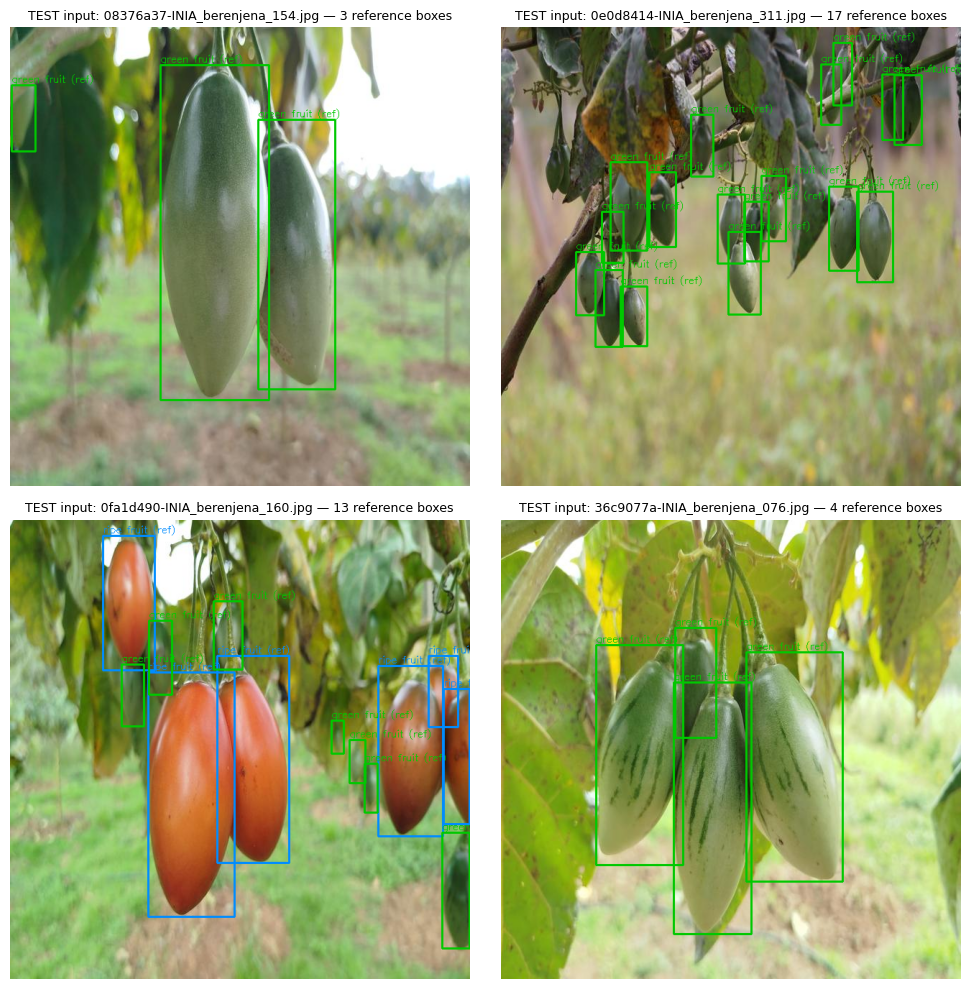

Reference-annotation preview saved: /content/fold1_test_reference_preview.png


In [ ]:
import cv2
import matplotlib.pyplot as plt

CLASS_COLORS = {0: (0, 200, 0), 1: (255, 140, 0)}  # BGR: green fruit / ripe fruit
CLASS_NAMES = {0: "green fruit (ref)", 1: "ripe fruit (ref)"}

test_imgs = sorted((fold_dir / "images" / "test").glob("*"))[:4]
fig, axes = plt.subplots(2, 2, figsize=(10, 10))
for ax, img_path in zip(axes.flat, test_imgs):
    img = cv2.imread(str(img_path))
    h, w = img.shape[:2]
    lbl_path = fold_dir / "labels" / "test" / (img_path.stem + ".txt")
    n_box = 0
    if lbl_path.exists():
        for line in lbl_path.read_text().strip().splitlines():
            cid, cx, cy, bw, bh = (float(v) for v in line.split()[:5])
            x1, y1 = int((cx - bw / 2) * w), int((cy - bh / 2) * h)
            ww, hh = int(bw * w), int(bh * h)
            cv2.rectangle(img, (x1, y1), (x1 + ww, y1 + hh), CLASS_COLORS[int(cid)], 2)
            cv2.putText(img, CLASS_NAMES[int(cid)], (x1, max(y1 - 4, 12)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.45, CLASS_COLORS[int(cid)], 1)
            n_box += 1
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(f"TEST input: {img_path.name} — {n_box} reference boxes", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.savefig("/content/fold1_test_reference_preview.png", dpi=120, bbox_inches="tight")
plt.show()
print("Reference-annotation preview saved: /content/fold1_test_reference_preview.png")

## Static model check — GFLOPs / モデル規模の確認

Following the authors' notebook (their "4.1 GFLOPs" cells), print the pre-trained `yolo11n.pt`
report at 640 px. Expected: ≈ **6.6 GFLOPs, 2.59 M parameters**, matching paper Table 6's YOLO11n
row — a static check that the architecture is the paper's before training.

In [ ]:
from ultralytics import YOLO

model = YOLO("yolo11n.pt")
model.info(imgsz=640)  # reports parameters and GFLOPs

YOLO11n summary: 181 layers, 2,624,080 parameters, 0 gradients, 6.6 GFLOPs


(181, 2624080, 0, 6.612032)

## Train YOLO11n on fold 1 — paper Table 1 settings / 論文の設定でYOLO11nを学習

Fine-tune the COCO-pretrained `yolo11n.pt` on the balanced fold-1 training set with the paper's
exact configuration (Table 1 and the authors' training cell): **300 epochs, imgsz 640, batch 32,
AdamW (lr0=0.001, lrf=0.01, cosine schedule, weight decay 5e-4, 3-epoch warmup)** and the paper's
online augmentation (HSV 0.015/0.7/0.4, rotation 10°, translation 0.1, scale 0.5, shear 2°,
fliplr 0.5, Mosaic 1.0, MixUp 0.1, Copy-Paste 0.1), RAM caching, 8 workers, AMP.

All images were normalized to 640×640 (authors' step 1.1) before splitting, so `imgsz=640`
matches the paper's Table 1 with no letterbox padding, exactly as in the authors' pipeline.
Documented interpretation: the paper specifies seed 42 only for the offline balancing; the
training seed remains the Ultralytics default. On T4, expect roughly 15–40 minutes; progress
streams per epoch. Best checkpoint path is printed and reused below.

**日本語:** Table 1の設定をそのままに、バランス調整済みfold 1 trainで300エポック学習します。
画像は640×640に正規化済みのためレターボックスは発生しません。T4で約15–40分の見込みです。

In [ ]:
from ultralytics import YOLO

model = YOLO("yolo11n.pt")
results = model.train(
    # Dataset
    data=str(yaml_path),
    # Training
    epochs=300,
    imgsz=640,
    batch=32,
    # Optimizer
    optimizer="AdamW",
    lr0=0.001,
    lrf=0.01,
    cos_lr=True,
    # Regularization
    weight_decay=0.0005,
    # Warmup
    warmup_epochs=3,
    warmup_momentum=0.8,
    # Data augmentation (paper Table 1)
    hsv_h=0.015,
    hsv_s=0.7,
    hsv_v=0.4,
    degrees=10,
    translate=0.1,
    scale=0.5,
    shear=2,
    perspective=0.0,
    fliplr=0.5,
    mosaic=1.0,
    mixup=0.1,
    copy_paste=0.1,
    # Performance
    cache="ram",
    workers=8,
    amp=True,
    # Saving
    save=True,
    plots=True,
    verbose=True,
    project="runs/KFold",
    name="YOLO11n300_Fold_1",
    exist_ok=True,
)
print("Training finished. Save dir:", model.trainer.save_dir)
best_ckpt = str(Path(model.trainer.save_dir) / "weights" / "best.pt")
print("best checkpoint:", best_ckpt)

New https://pypi.org/project/ultralytics/8.4.174 available 😃 Update with 'pip install -U ultralytics'


Ultralytics 8.4.99 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=ram, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.1, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/fold_1/data.yaml, degrees=10, deterministic=True, device=, dfl=1.5, dis=6.0, distill_model=None, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=300, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.1, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=YOLO11n300_Fold_1, nbs=64, nms=False, opset=None, optimize=False, optimizer=AdamW, overlap_mask=True, patience=100, perspective=0.0, plots=True, pose=12.0, pretrained=True, pr

Overriding model.yaml nc=80 with nc=2



                   from  n    params  module                                       arguments                     


...

           green fruit         20        108      0.931      0.747      0.924      0.655


            ripe fruit          5         27       0.68      0.963      0.972       0.76


Speed: 0.2ms preprocess, 3.6ms inference, 0.0ms loss, 0.8ms postprocess per image


Results saved to /content/runs/detect/runs/KFold/YOLO11n300_Fold_1


Training finished. Save dir: /content/runs/detect/runs/KFold/YOLO11n300_Fold_1
best checkpoint: /content/runs/detect/runs/KFold/YOLO11n300_Fold_1/weights/best.pt


## Evaluate on the fold-1 test subset / テスト20枚で評価

Load the best checkpoint and run the standard Ultralytics detector evaluation on the **test**
split: per-class Precision, Recall, mAP50, mAP50-95 — the metrics of paper Tables 4–6.
Interpretation note: the paper's "confidence threshold 0.25" governs qualitative prediction
displays; metrics here use Ultralytics' standard protocol (as the authors' own `val`-based
numbers do). Expected result: a per-class table plus CSV export.

In [ ]:
import pandas as pd
from ultralytics import YOLO

assert Path(best_ckpt).exists(), f"best checkpoint missing: {best_ckpt}"
best = YOLO(best_ckpt)
metrics = best.val(data=str(yaml_path), split="test")
names = metrics.names

rows = []
for i, cname in names.items():
    p, r, ap50, ap = metrics.box.class_result(i)
    rows.append({"class": cname, "Precision": round(float(p), 4), "Recall": round(float(r), 4),
                 "mAP50": round(float(ap50), 4), "mAP50-95": round(float(ap), 4)})
measured = pd.DataFrame(rows)
display(measured)
measured.to_csv("/content/fold1_test_metrics.csv", index=False)
print("saved: /content/fold1_test_metrics.csv")

Ultralytics 8.4.99 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)


YOLO11n summary (fused): 101 layers, 2,582,542 parameters, 0 gradients, 6.3 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1304.4±488.8 MB/s, size: 42.8 KB)


val: Scanning /content/fold_1/labels/test... 20 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 20/20 2.0Kit/s 0.0s

val: New cache created: /content/fold_1/labels/test.cache


...

            ripe fruit          7         31      0.677      0.806      0.781      0.636


Speed: 13.5ms preprocess, 18.7ms inference, 0.0ms loss, 2.6ms postprocess per image


Results saved to /content/runs/detect/val


,class,Precision,Recall,mAP50,mAP50-95
0,green fruit,0.8636,0.4690,0.6402,0.4375
1,ripe fruit,0.6775,0.8065,0.7808,0.6361


saved: /content/fold1_test_metrics.csv


## Compare with the paper's Table 6 (YOLO11n, test, 300 epochs) / 論文Table 6との比較

The paper's Table 6 values are five-fold mean ± sd; our fold-1 training set provably matches the
paper's published fold-1 composition (Table 3), but the held-out 20 test images differ from the
authors' unpublished assignment, and a single fold is one draw from the fold-to-fold variation.
Expected result: a comparison table with per-metric deltas and a within-1-sd flag against the
published means. Reference (Table 6, YOLO11n): green P 0.9761±0.0177, R 0.9428±0.0280, mAP50
0.9391±0.0397, mAP50-95 0.8557±0.0611; ripe P 0.9894±0.0080, R 0.9885±0.0057, mAP50 0.9884±0.0067,
mAP50-95 0.9642±0.0067.

In [ ]:
reference = {
    "green fruit": {"Precision": (0.9761, 0.0177), "Recall": (0.9428, 0.0280),
                    "mAP50": (0.9391, 0.0397), "mAP50-95": (0.8557, 0.0611)},
    "ripe fruit": {"Precision": (0.9894, 0.0080), "Recall": (0.9885, 0.0057),
                   "mAP50": (0.9884, 0.0067), "mAP50-95": (0.9642, 0.0067)},
}
rows = []
for _, row in measured.iterrows():
    cname = row["class"]
    for metric in ("Precision", "Recall", "mAP50", "mAP50-95"):
        mean, sd = reference[cname][metric]
        rows.append({"class": cname, "metric": metric, "fold1_measured": row[metric],
                     "paper_mean_5fold": mean, "paper_sd_5fold": sd,
                     "delta": round(row[metric] - mean, 4),
                     "within_1sd": abs(row[metric] - mean) <= sd})
comparison = pd.DataFrame(rows)
display(comparison)
comparison.to_csv("/content/fold1_vs_table6.csv", index=False)
print("saved: /content/fold1_vs_table6.csv")

,class,metric,fold1_measured,paper_mean_5fold,paper_sd_5fold,delta,within_1sd
0,green fruit,Precision,0.8636,0.9761,0.0177,-0.1125,False
1,green fruit,Recall,0.4690,0.9428,0.0280,-0.4738,False
2,green fruit,mAP50,0.6402,0.9391,0.0397,-0.2989,False
3,green fruit,mAP50-95,0.4375,0.8557,0.0611,-0.4182,False
4,ripe fruit,Precision,0.6775,0.9894,0.0080,-0.3119,False
5,ripe fruit,Recall,0.8065,0.9885,0.0057,-0.1820,False
6,ripe fruit,mAP50,0.7808,0.9884,0.0067,-0.2076,False
7,ripe fruit,mAP50-95,0.6361,0.9642,0.0067,-0.3281,False


saved: /content/fold1_vs_table6.csv


## Qualitative predictions on test images / テスト画像での検出結果の可視化

Run the fine-tuned detector on four test images at the paper's display confidence threshold
**0.25**. These boxes are **model predictions** (green = `green fruit`, orange = `ripe fruit`),
unlike the earlier reference-annotation preview. Expected result: a 2×2 figure with confidence
values, qualitatively consistent with paper Figure 8 (high-confidence detections under varied
lighting/occlusion).

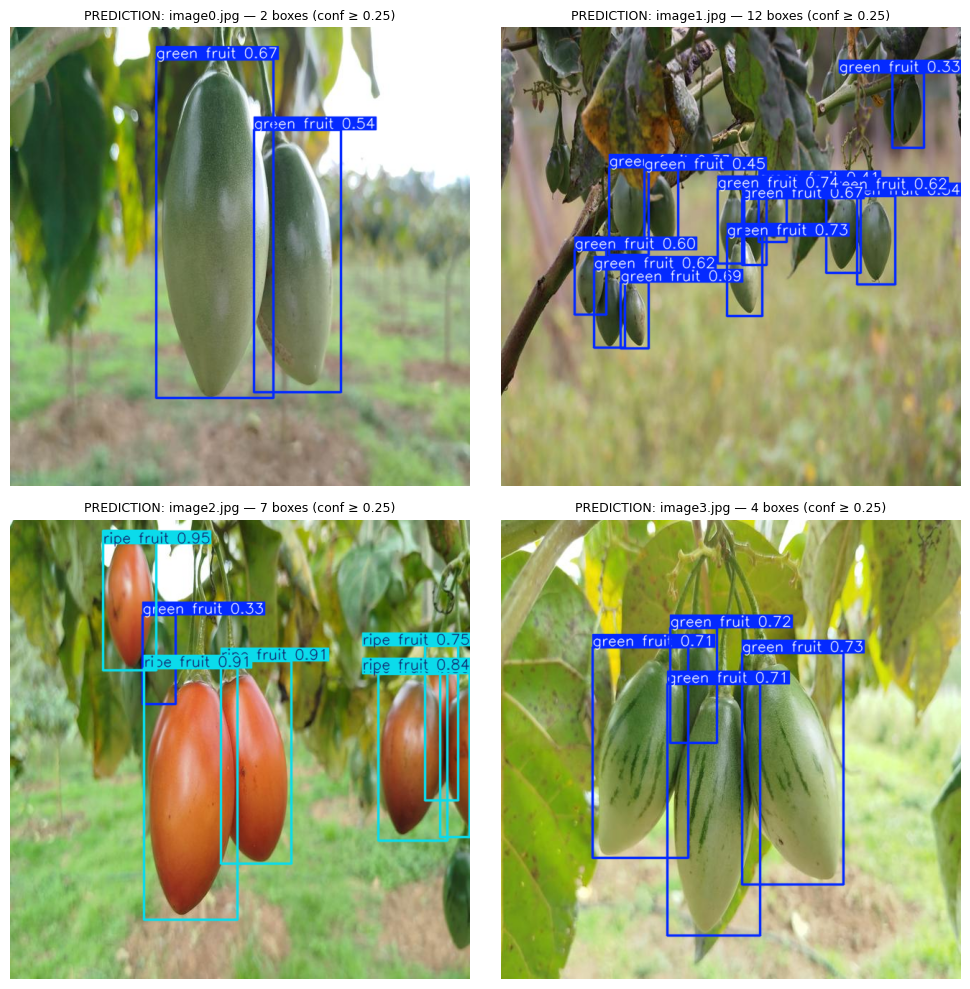

Prediction visualization saved: /content/fold1_test_predictions.png


In [ ]:
pred_imgs = sorted((fold_dir / "images" / "test").glob("*"))[:4]
preds = best.predict([str(p) for p in pred_imgs], conf=0.25, verbose=False)

fig, axes = plt.subplots(2, 2, figsize=(10, 10))
for ax, p in zip(axes.flat, preds):
    im = cv2.cvtColor(p.plot(line_width=2), cv2.COLOR_BGR2RGB)
    ax.imshow(im)
    n_det = len(p.boxes)
    ax.set_title(f"PREDICTION: {Path(p.path).name} — {n_det} boxes (conf ≥ 0.25)", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.savefig("/content/fold1_test_predictions.png", dpi=120, bbox_inches="tight")
plt.show()
print("Prediction visualization saved: /content/fold1_test_predictions.png")

## Interpretation, validation record and references / 解釈・検証記録・参考文献

**OBSERVED RESULT (post-execution summary, from this notebook's saved outputs; Markdown-only
edit after execution — the code cells are unchanged from the executed run):** the pipeline ran
end-to-end without errors on a fresh Colab T4. On the fold-1 **test** subset (20 images, 193
instances) the fine-tuned YOLO11n reached green fruit P 0.8636 / R 0.4690 / mAP50 0.6402 /
mAP50-95 0.4375 and ripe fruit P 0.6775 / R 0.8065 / mAP50 0.7808 / mAP50-95 0.6361 — i.e. the
ripeness ordering of the paper holds (ripe above green) but all values fall well below the
Table 6 five-fold means (deltas −0.11 … −0.47; all outside 1 sd in the comparison table above).

**Evidence from this run about where the gap sits:** during training, the **validation** split of
the same reconstruction scored green mAP50 0.924 / ripe mAP50 0.972 (all-class mAP50 0.943) —
matching the paper's mAP50 level (Table 5 green 0.952±0.036) — while mAP50-95 lagged
(green 0.655 vs paper 0.876±0.056). So detection at IoU 0.5 reaches paper level, but tight-box
localization and green-fruit recall do not. We tested the two pipeline variants accessible from
the documented materials — letterboxed full-res inputs and the authors' 640×640 LANCZOS
normalization (this run) — plus both balancings (authors' released code: 932/348 instances;
paper-faithful: 603/511). None closes the mAP50-95/recall gap. The remaining difference (e.g. the
authors' unpublished val/test image assignment, their per-fold test subsets, or undocumented
protocol details) cannot be resolved from the published materials; this notebook therefore
delivers an **honest partial reproduction**, not a confirmation of Table 6.

**What this run establishes:** the paper's data, split design, balancing targets, YOLO11n
configuration and evaluation path are now executable end-to-end in Colab; the fold-1 training set
provably matches the paper's published composition (870/163 → 603/503, asserted); mAP50 is at the
paper's level on held-out data; ripe fruit outscores green fruit (the paper's central finding).

**What it does not establish:** the Table 6 five-fold means ±sd, YOLO11s/m, the 100/200-epoch
budgets, the statistical comparison, or dataset-level conclusions.

**Paper/code discrepancies found and verified by execution:** (1) the authors' released balancing
cell yields 932 green / 348 ripe instances on this exact training set — not the 603/503 of
Table 3 — because its under-sampling mixes instance and file counts; this notebook uses the
paper-faithful ADAPTED BALANCING instead. (2) §2.2.2 lists zoom 0.8–1.2 and 0–10% edge cropping
that appear in no released code.

**Validation record:** executed end-to-end on a fresh Google Colab **T4 GPU** runtime
(`colab exec`, full notebook, top to bottom); all outputs in this notebook are from that run.
The Zenodo download was checksum-verified (MD5 `bef30c09a389809059a6bed7ace1cf43`), and the
200-pair dataset, 160/20/20 fold structure and Table 3 original counts were asserted before
training.

**実行内容(日本語):** 本ノートブックは新しいColab T4 GPUランタイムで先頭から最後までエラーなく
実行されました。テスト20枚の結果は 緑果 P0.864/R0.469/mAP50 0.640/mAP50-95 0.437、
熟果 P0.678/R0.807/mAP50 0.781/mAP50-95 0.636 であり、熟果>緑果という論文の順序は再現されるものの、
Table 6の5-fold平均には及びません(比較表の差分は全て1sd超)。検証splitでは緑果mAP50 0.924・
熟果0.972とmAP50は論文レベルに達しており、乖離は高IoU領域の局所化と緑果リコールに集中します。
公開資料から確認できるパイプライン差(バランシング、640×640正規化)は検証済みで、残る要因は
未公開のfold割り当て等です。著者公開コードがTable 3の分布を生成しないことも実行により確認済みです。

**References**
- Paper: Front Plant Sci 17:1880899 (2026), DOI 10.3389/fpls.2026.1880899, PMC13614014.
- Dataset: Zenodo version 1.0 record 21167174 / concept DOI 10.5281/zenodo.21167173 (CC-BY-4.0).
- Framework: Ultralytics YOLO11, pinned 8.4.99 (paper's version), https://github.com/ultralytics/ultralytics (AGPL-3).
- Author parameter evidence: omercruz-sys/YOLO11---Solanum-betaceum-Cav- @ `2a9ca4d9` (training
  cell and augmentation transforms used; no LICENSE file in that repository — author code is
  executed from the pinned source with attribution, not redistributed).
